<a href="https://colab.research.google.com/github/deepak-kumar-da/smart-comment-classifier/blob/main/notebooks/03_exploratory_data_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive',force_remount=True)

import os
import re
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
from IPython.display import display

BASE = "/content/drive/MyDrive/Smart_Comment_Classifier"
PROCESSED = f"{BASE}/datasets/processed"
REPORTS = f"{BASE}/datasets/reports"
OUTPUTS = f"{BASE}/outputs"

os.makedirs(REPORTS,exist_ok=True)
os.makedirs(OUTPUTS,exist_ok=True)

sns.set_theme(style="whitegrid")

Mounted at /content/drive


In [ ]:
# load datasets

files = {
    "jigsaw":"jigsaw_toxicity_final.csv",
    "uci_spam":"uci_spam_final.csv",
    "youtube_spam":"youtube_spam_final.csv",
    "youtube_toxicity":"youtube_toxicity_final.csv",
    "spamid":"spamid_indonesian_separate.csv"
}

eda_data = {}

for name,filename in files.items():
  path = os.path.join(PROCESSED,filename)
  if not os.path.exists(path):
    raise FileNotFoundError(f"Missing file: {path}")
  eda_data[name] = pd.read_csv(path)
  print(f"{name}:{eda_data[name].shape}")

jigsaw = eda_data["jigsaw"]
uci = eda_data["uci_spam"]
youtube_spam = eda_data["youtube_spam"]
youtube_toxicity = eda_data["youtube_toxicity"]
spamid = eda_data["spamid"]

jigsaw:(159272, 9)
uci_spam:(1741, 4)
youtube_spam:(14032, 4)
youtube_toxicity:(14034, 4)
spamid:(72873, 6)


In [ ]:
overview = []

for name,df in eda_data.items():
  overview.append({
      "dataset":name,
      "rows":len(df),
      "columns":len(df.columns),
      "missing_text":df["text"].isna().sum(),
      "unique_comments":df["text"].nunique(),
      "duplicate_comments":df["text"].duplicated().sum()
  })

overview_df = pd.DataFrame(overview)

display(overview_df)

overview_df.to_csv(
    os.path.join(REPORTS,"eda_dataset_overview.csv"),
    index=False
)

,dataset,rows,columns,missing_text,unique_comments,duplicate_comments
0,jigsaw,159272,9,0,159272,0
1,uci_spam,1741,4,0,1741,0
2,youtube_spam,14032,4,0,14032,0
3,youtube_toxicity,14034,4,0,14034,0
4,spamid,72873,6,0,44623,28250


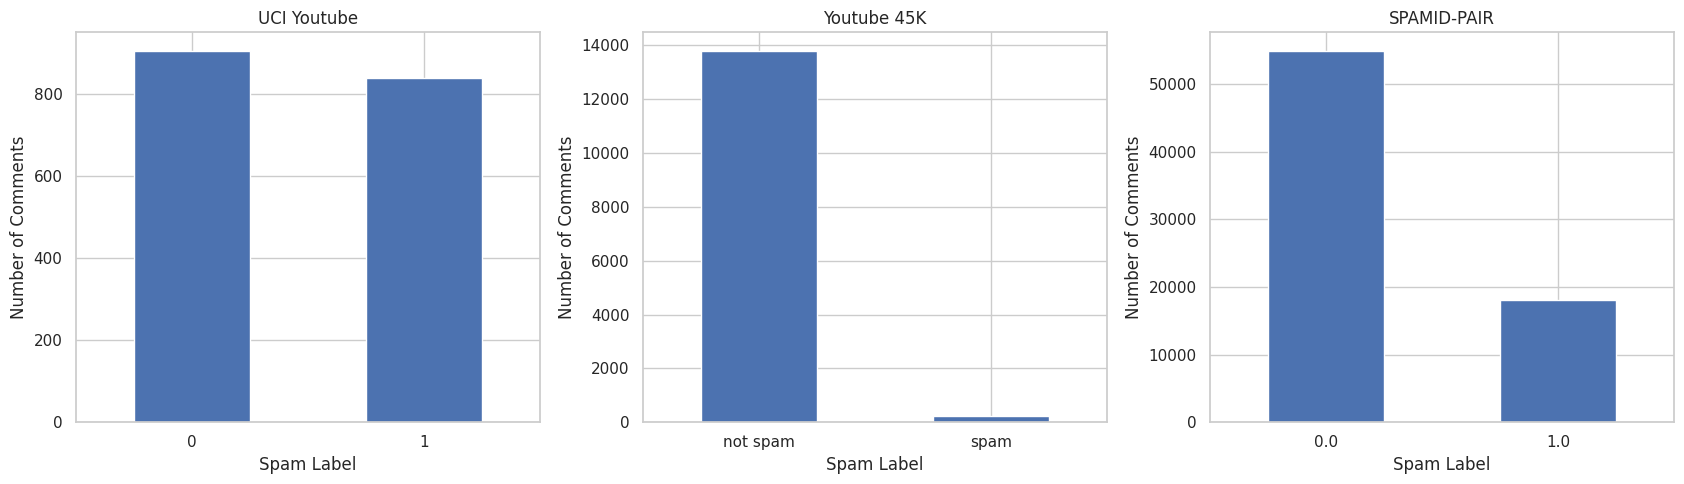

In [ ]:
# spam class distribution

spam_datasets = {
    "UCI Youtube":uci,
    "Youtube 45K":youtube_spam,
    "SPAMID-PAIR":spamid
}

spam_label_reports = {}

fig,axes = plt.subplots(1,3,figsize = (17,5))

for ax,(name,df) in zip(axes,spam_datasets.items()):
  counts = df["label"].value_counts(dropna=False)
  spam_label_reports[name] = {
      str(k):int(v) for k,v in counts.items()
  }
  counts.plot(kind="bar",ax=ax)
  ax.set_title(name)
  ax.set_xlabel("Spam Label")
  ax.set_ylabel("Number of Comments")
  ax.tick_params(axis='x',rotation=0)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUTS,"spam_class_distributions.png"),dpi=150,bbox_inches="tight")
plt.show()

,positive_count,negative_count,positive_percentage
toxic,15215,144057,9.552840
severe_toxic,1585,157687,0.995153
obscene,8407,150865,5.278392
threat,469,158803,0.294465
insult,7835,151437,4.919258
identity_hate,1394,157878,0.875232


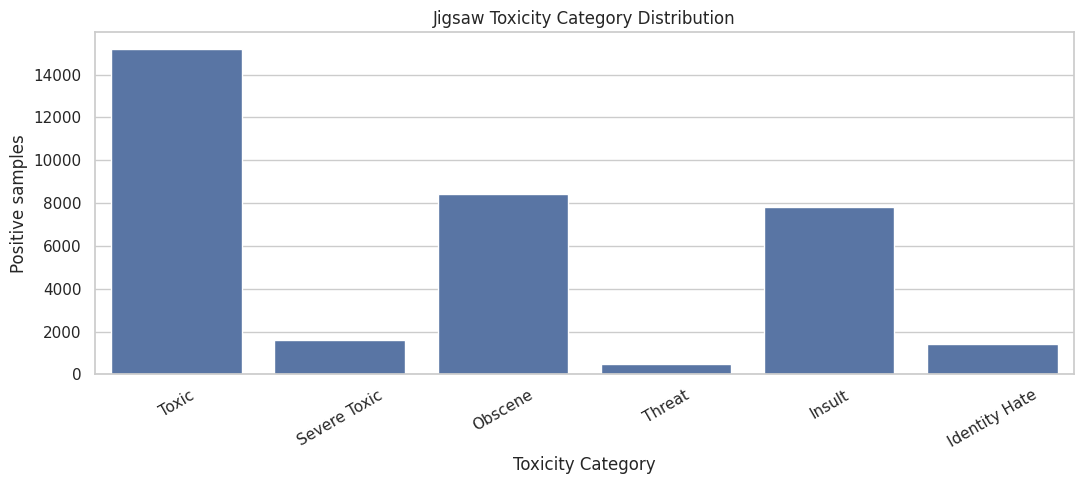

In [ ]:
# toxicity label distributions

toxicity_labels = [
    "toxic",
    "severe_toxic",
    "obscene",
    "threat",
    "insult",
    "identity_hate"
]

toxicity_counts = jigsaw[toxicity_labels].sum()

toxicity_report = pd.DataFrame({
    "positive_count":toxicity_counts,
    "negative_count":len(jigsaw)-toxicity_counts
})

toxicity_report["positive_percentage"] = (toxicity_report["positive_count"]/len(jigsaw)*100)

display(toxicity_report)

plt.figure(figsize=(11,5))

sns.barplot(
    x=toxicity_report.index,
    y=toxicity_report["positive_count"]
)

plt.title("Jigsaw Toxicity Category Distribution")

# Fix: Set the ticks explicitly before renaming tick labels
ax = plt.gca()
ax.set_xticks(range(len(toxicity_labels)))
ax.set_xticklabels([label.replace('_', ' ').title() for label in toxicity_labels])

plt.xlabel("Toxicity Category")
plt.ylabel("Positive samples")
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUTS,"toxicity_class_distribution.png"),dpi=150,bbox_inches="tight")
plt.show()

label
non-toxic    13258
toxic          776
Name: count, dtype: int64


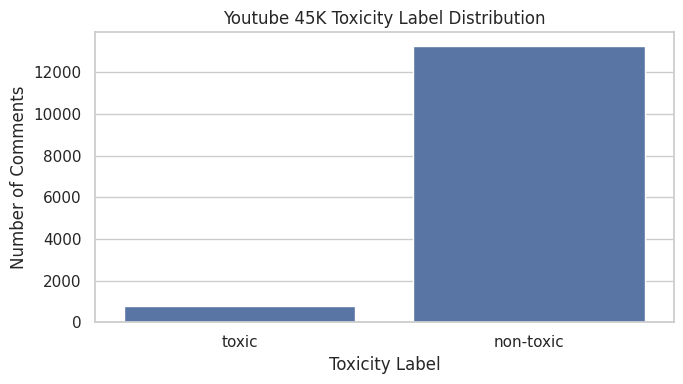

In [ ]:
# youtube 45k toxicity distribution

print(youtube_toxicity["label"].value_counts(dropna=False))

plt.figure(figsize=(7,4))

sns.countplot(
    data=youtube_toxicity,
    x="label"
)

plt.title("Youtube 45K Toxicity Label Distribution")
plt.xlabel("Toxicity Label")
plt.ylabel("Number of Comments")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUTS,"youtube_toxicity_distribution.png"),dpi=150,bbox_inches="tight")
plt.show()

In [ ]:
# text statistics

def add_text_features(df):
  result = df.copy()
  result["char_count"] = result["text"].astype(str).str.len()
  result["word_count"] = result["text"].astype(str).str.split().str.len()
  result["uppercase_count"] = result["text"].astype(str).apply(lambda x: sum(c.isupper() for c in x))
  result["url_count"] = result["text"].astype(str).apply(lambda x: len(re.findall(r"https?://\S+|www\.\S+",x)))
  result["exclamation_count"] = result["text"].astype(str).str.count("!")
  result["question_count"] = result["text"].astype(str).str.count("\?")

  return result

for name in eda_data:
  eda_data[name] = add_text_features(eda_data[name])

jigsaw = eda_data["jigsaw"]
uci = eda_data["uci_spam"]
youtube_spam = eda_data["youtube_spam"]
youtube_toxicity = eda_data["youtube_toxicity"]
spamid = eda_data["spamid"]

<>:10: SyntaxWarning: invalid escape sequence '\?'
<>:10: SyntaxWarning: invalid escape sequence '\?'
/tmp/ipykernel_1540/2392375501.py:10: SyntaxWarning: invalid escape sequence '\?'
  result["question_count"] = result["text"].astype(str).str.count("\?")


In [ ]:
length_summary = []

for name,df in eda_data.items():
  length_summary.append({
      "dataset":name,
      "average_characters":df["char_count"].mean(),
      "median_characters":df["char_count"].median(),
      "average_words":df["word_count"].mean(),
      "median_words":df["word_count"].median(),
      "maximum_words":df["word_count"].max()
  })

length_df = pd.DataFrame(length_summary)

display(length_df.round(2))

length_df.to_csv(os.path.join(REPORTS,"eda_text_length_summary.csv"),index=False)

,dataset,average_characters,median_characters,average_words,median_words,maximum_words
0,jigsaw,394.10,205.0,67.28,36.0,1411
1,uci_spam,96.96,53.0,15.78,8.0,213
2,youtube_spam,95.17,51.0,16.71,9.0,1021
3,youtube_toxicity,95.19,51.0,16.71,9.0,1021
4,spamid,33.70,13.0,5.41,2.0,387


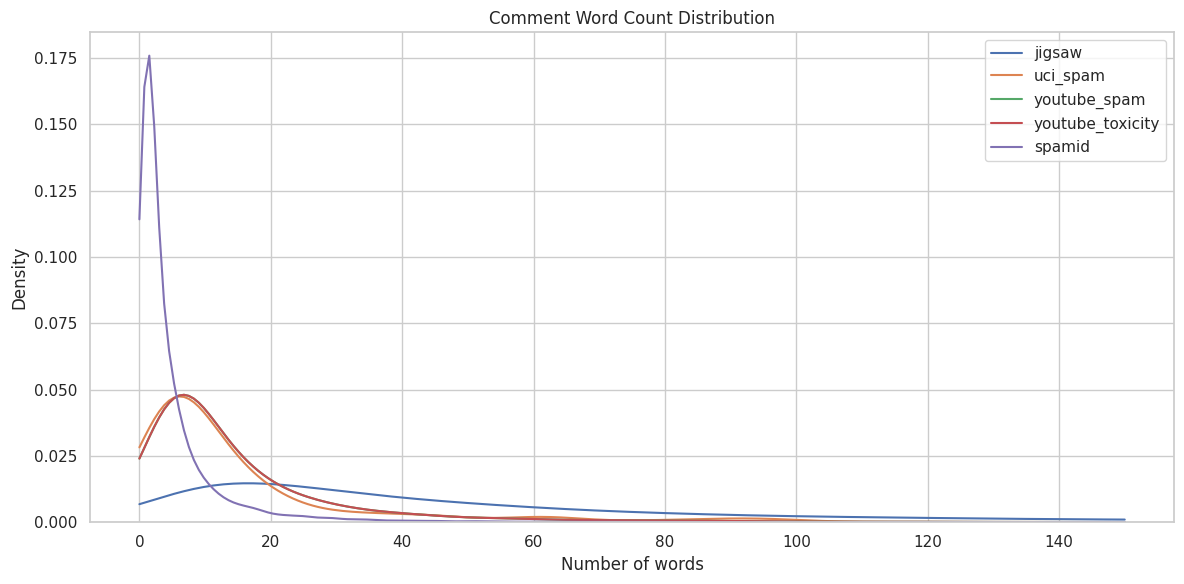

In [ ]:
# word count distribution

plt.figure(figsize=(12,6))

for name,df in eda_data.items():
  sns.kdeplot(
      data=df,
      x="word_count",
      label=name,
      fill=False,
      clip=(0,150)
  )

plt.title("Comment Word Count Distribution")
plt.xlabel("Number of words")
plt.ylabel("Density")
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(OUTPUTS,"word_count_comparison.png"),dpi=150,bbox_inches="tight")
plt.show()

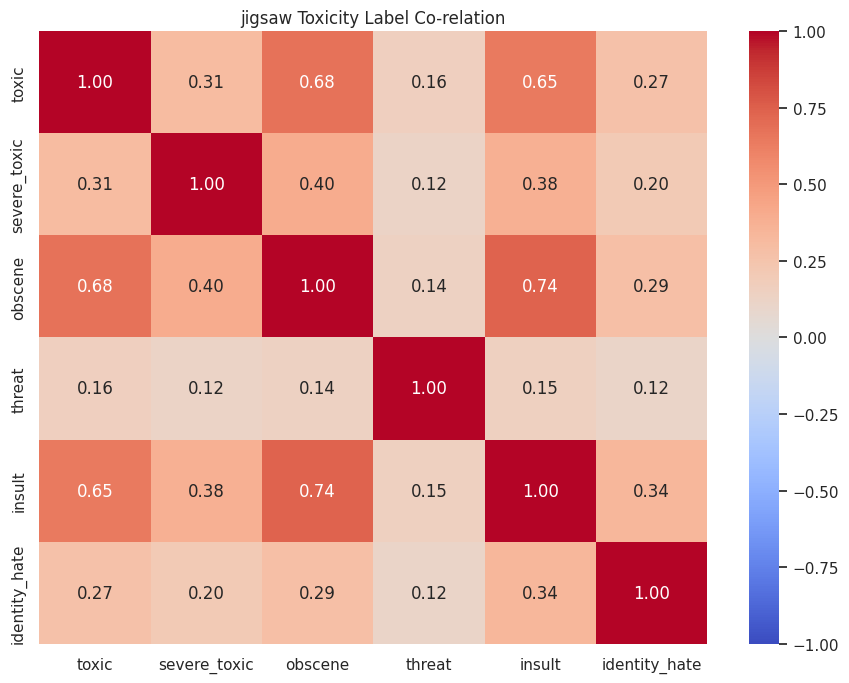

In [ ]:
# Multi label toxicity co-occurence

cooccurence = jigsaw[toxicity_labels].corr()

plt.figure(figsize=(9,7))

sns.heatmap(
    cooccurence,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.title("jigsaw Toxicity Label Co-relation")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUTS,"toxicity_label_corelation.png"),dpi=150,bbox_inches="tight")
plt.show()

No. of active toxicity labels per comment:
toxicity_label_count
0    143131
1      6331
2      3463
3      4187
4      1744
5       385
6        31
Name: count, dtype: int64


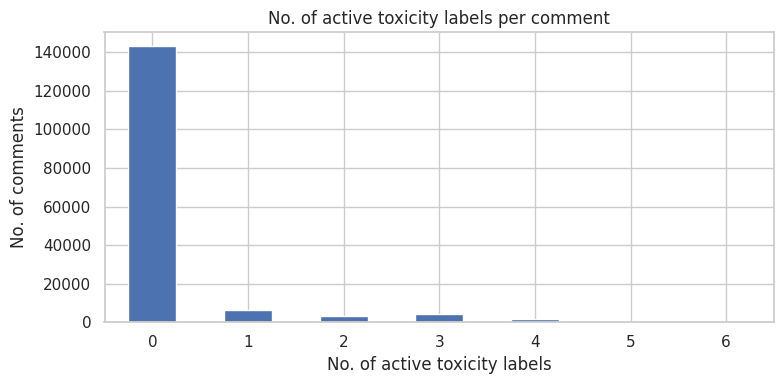

In [ ]:
# toxicity labels appear together

jigsaw["toxicity_label_count"] = jigsaw[toxicity_labels].sum(axis=1)
cooccurence_counts = jigsaw["toxicity_label_count"].value_counts().sort_index()

print("No. of active toxicity labels per comment:")
print(cooccurence_counts)

plt.figure(figsize=(8,4))

cooccurence_counts.plot(kind="bar")

plt.title("No. of active toxicity labels per comment")
plt.xlabel("No. of active toxicity labels")
plt.ylabel("No. of comments")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUTS,"toxicity_label_count.png"),dpi=150,bbox_inches="tight")
plt.show()

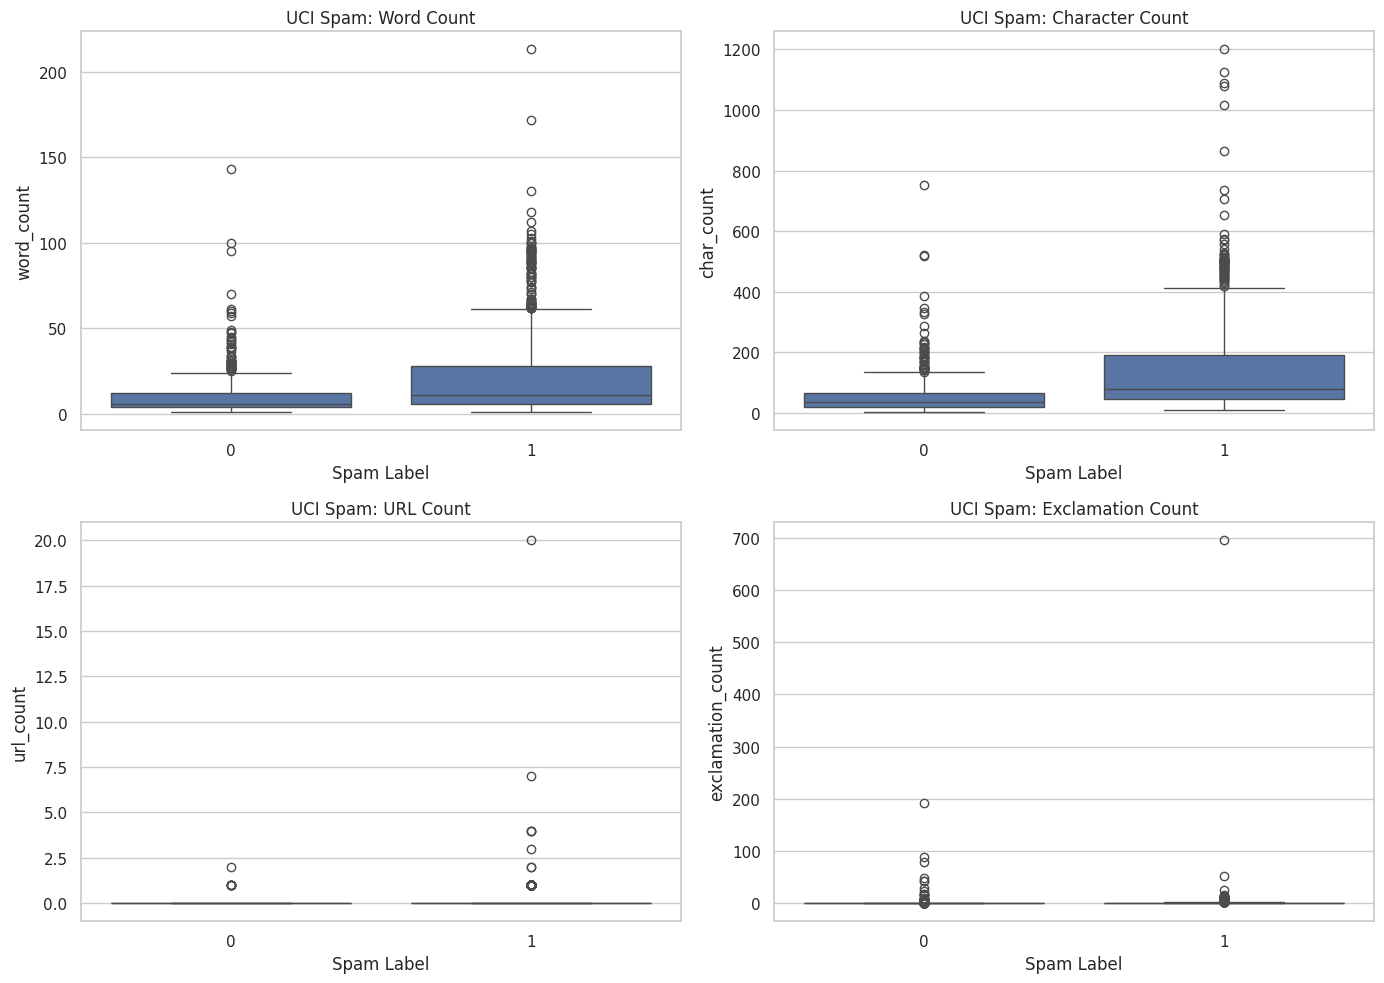

In [ ]:
# spam vs non spam text features

fig, axes = plt.subplots(2,2,figsize=(14,10))

for ax, (feature,title) in zip(
    axes.flatten(),
    [
        ("word_count","Word Count"),
        ("char_count","Character Count"),
        ("url_count","URL Count"),
        ("exclamation_count","Exclamation Count")
    ]
):

  sns.boxplot(data=uci,x="label",y=feature,ax=ax)
  ax.set_title(f"UCI Spam: {title}")
  ax.set_xlabel("Spam Label")

plt.tight_layout()
plt.savefig(os.path.join(OUTPUTS,"uci_spam_text_features.png"),dpi=150,bbox_inches="tight")
plt.show()

In [ ]:
# url and punctuation patterns

for name,df in {
    "UCI" :uci,
    "Youtube 45K":youtube_spam,
    "SPAMID-PAIR":spamid
}.items():

  print(f"\n{name}")
  for label,group in df.groupby("label"):
    print(
        f"Label {label}:"
        f"URL-containing comments= "
        f"{(group['url_count'] > 0).mean()*100:.2f}%"
    )

    print(
        f"Label {label}:"
        f"Average word count= "
        f"{group['word_count'].mean():.2f}"
    )

    print(
        f"Label {label}:"
        f"Average exclamation count= "
        f"{group['exclamation_count'].mean():.2f}"
    )


UCI
Label 0:URL-containing comments= 0.88%
Label 0:Average word count= 9.44
Label 0:Average exclamation count= 1.12
Label 1:URL-containing comments= 22.70%
Label 1:Average word count= 22.62
Label 1:Average exclamation count= 1.81

Youtube 45K
Label not spam:URL-containing comments= 0.00%
Label not spam:Average word count= 16.40
Label not spam:Average exclamation count= 0.11
Label spam:URL-containing comments= 85.71%
Label spam:Average word count= 34.14
Label spam:Average exclamation count= 0.39

SPAMID-PAIR
Label 0.0:URL-containing comments= 0.02%
Label 0.0:Average word count= 3.93
Label 0.0:Average exclamation count= 0.02
Label 1.0:URL-containing comments= 1.73%
Label 1.0:Average word count= 9.92
Label 1.0:Average exclamation count= 0.09


In [ ]:
# real examples

for name,df in eda_data.items():
  print(f"\n{'='*60}")
  print(name.upper())
  print('='*60)

  sample_columns = ["text"]

  if "label" in df.columns:
    sample_columns.append("label")

  if name == "jigsaw":
    sample_columns += toxicity_labels

  display(df[sample_columns].sample(min(5,len(df)),random_state=42))


JIGSAW


,text,toxic,severe_toxic,obscene,threat,insult,identity_hate
70971,STOP VANDALIZING \n\nPlease stop your disrupti...,0,0,0,0,0,0
94340,""":To the unsigned poster above: If a person do...",0,0,0,0,0,0
143043,"""\nNo, it does not. The """"world's third oldes...",0,0,0,0,0,0
98454,Have you not read this article?!!,0,0,0,0,0,0
80907,"""\n\n False accusation \n\nYou have falsely ac...",0,0,0,0,0,0



UCI_SPAM


,text,label
482,I &lt;3 Katy Perry!﻿,0
1507,Best World Cup Song﻿,0
950,Check out my dance videos!! You won&#39;t be d...,1
1005,Hey I&#39;m a British youtuber!!<br />I upload...,1
705,I love this song so much﻿,0



YOUTUBE_SPAM


,text,label
7142,Cleanliness and quality of life also need to b...,not spam
9671,Use less fellows,not spam
3111,"Pakistan has better foreign policy than India,...",not spam
327,All are north Indian rss terrorist,not spam
4098,Kerch strait,not spam



YOUTUBE_TOXICITY


,text,label
353,Foolish people,toxic
13561,Background sound was good today 😅.,non-toxic
13806,"#bologuruji Hello Sir, agar ham android mobile...",non-toxic
11094,Any one in 2025,non-toxic
8192,Congratulation to team India for this outstand...,non-toxic



SPAMID


,text,label
36793,MasyaAllah jilbab hijau Syegeer sekaliiii 🤩🤩❤️,0.0
36362,❤️,0.0
47608,Great,0.0
20409,idola gw mamsky mamaa gigi ❤️❤️❤️❤️,0.0
7220,😍😍,0.0


In [ ]:
# saving report

eda_report = {
    "dataset_overview":overview_df.to_dict(orient="records"),
    "spam_label_distribution":spam_label_reports,
    "toxicity_label_distribution":{
        str(k):int(v)
        for k,v in toxicity_counts.items()
    },
    "text_length_summary":length_df.to_dict(orient="records"),
    "jigsaw_toxicity_cooccurence":{
        str(k):int(v)
        for k,v in cooccurence_counts.items()
    }
}

report_path = os.path.join(REPORTS,"notebook_03_eda_report.json")

with open(report_path,"w") as f:
  json.dump(eda_report,f,indent=4,default=str)

print("EDA report saved:",report_path)

print("\nGenerated visualization files:")
for filename in os.listdir(OUTPUTS):
  if filename.endswith(".png"):
    print(filename)

EDA report saved: /content/drive/MyDrive/Smart_Comment_Classifier/datasets/reports/notebook_03_eda_report.json

Generated visualization files:
spam_class_distributions.png
toxicity_class_distribution.png
youtube_toxicity_distribution.png
word_count_comparison.png
toxicity_label_corelation.png
toxicity_label_count.png
uci_spam_text_features.png
